In [1]:
import pandas as pd
import numpy as np
import random
import librosa
import os

from sklearn.metrics import f1_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, accuracy_score

from IPython.display import Audio, display
print("done")

done


In [2]:
features_df = pd.read_csv("skrillex2015_features.csv")
transitions_df = pd.read_csv("skrillex2015_transitions.csv")

print(features_df.columns)
print(transitions_df.head())

Index(['Unnamed: 0', 'tempo', 'rms', 'centroid', 'flux', 'mfcc_0', 'mfcc_1',
       'mfcc_2', 'mfcc_3', 'mfcc_4', 'mfcc_5', 'mfcc_6', 'mfcc_7', 'mfcc_8',
       'mfcc_9', 'mfcc_10', 'mfcc_11', 'mfcc_12', 'track_id'],
      dtype='object')
   Unnamed: 0  from_track  to_track  delta_tempo  delta_rms  delta_centroid  \
0           0           0         1     0.000000  -0.007684      110.187534   
1           1           1         2   -52.615066   0.027054     -223.246427   
2           2           2         3    52.615066  -0.054642      346.407079   
3           3           3         4     0.000000   0.001285       32.823633   
4           4           4         5     0.000000   0.009693      -11.844465   

   delta_flux  delta_mfcc_0  delta_mfcc_1  delta_mfcc_2  delta_mfcc_3  \
0   -0.001972     11.975159      0.822058     -4.808348     -4.341584   
1    0.109363    -14.978062     -1.972160     -2.431379      6.009135   
2   -0.010915     12.155312      2.601774      2.075849    -10.8422

In [3]:
skrillex_cols = [
    'tempo',
    'rms',
    'centroid',
    'flux',
    'mfcc_0',
    'mfcc_1',
    'mfcc_2',
    'mfcc_3',
    'mfcc_4'
]

for col in skrillex_cols:
    features_df[col] = (
        features_df[col]
        .astype(str)
        .str.strip("[]")
        .astype(float)
    )

In [4]:
def clean_value(x):
    # Convert "[123.45]" → 123.45
    if isinstance(x, str):
        x = x.strip("[]")
    return float(x)


def get_track_features(track_id):
    row = features_df[features_df['track_id'] == track_id]
    
    if len(row) == 0:
        return None
    
    vals = row.iloc[0][skrillex_cols]
    
    # Clean every value
    cleaned = [clean_value(v) for v in vals]
    
    return np.array(cleaned)

In [5]:
X = []
y = []

print("Transition columns:", transitions_df.columns.tolist())

# -------------------------------
# Positive transitions (REAL DJ)
# -------------------------------
for _, row in transitions_df.iterrows():
    f1 = get_track_features(row['from_track'])
    f2 = get_track_features(row['to_track'])

    if f1 is not None and f2 is not None:
        diff = np.abs(f1 - f2)
        X.append(diff)
        y.append(1)

print("Positive samples:", len(X))


# -------------------------------
# Negative samples (RANDOM)
# -------------------------------
all_tracks = features_df['track_id'].tolist()

transition_pairs = set(zip(
    transitions_df['from_track'],
    transitions_df['to_track']
))

target_size = len(X) * 2

while len(y) < target_size:
    t1, t2 = random.sample(all_tracks, 2)

    if (t1, t2) not in transition_pairs:
        f1 = get_track_features(t1)
        f2 = get_track_features(t2)

        if f1 is not None and f2 is not None:
            diff = np.abs(f1 - f2)
            X.append(diff)
            y.append(0)

print("Total samples:", len(X))
print("Positive:", sum(y))
print("Negative:", len(y) - sum(y))

Transition columns: ['Unnamed: 0', 'from_track', 'to_track', 'delta_tempo', 'delta_rms', 'delta_centroid', 'delta_flux', 'delta_mfcc_0', 'delta_mfcc_1', 'delta_mfcc_2', 'delta_mfcc_3', 'delta_mfcc_4', 'delta_mfcc_5', 'delta_mfcc_6', 'delta_mfcc_7', 'delta_mfcc_8', 'delta_mfcc_9', 'delta_mfcc_10', 'delta_mfcc_11', 'delta_mfcc_12']
Positive samples: 31
Total samples: 62
Positive: 31
Negative: 31


In [6]:
X = np.array(X)
y = np.array(y)

y = np.array(y).astype(int)
print("Unique labels:", np.unique(y))
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

Unique labels: [0 1]


In [7]:
model = MLPClassifier(hidden_layer_sizes=(64, 32), alpha=.01, max_iter=300, random_state=42)
model.fit(X_train, y_train)

preds = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, preds))
print(classification_report(y_test, preds))

Accuracy: 0.9230769230769231
              precision    recall  f1-score   support

           0       0.86      1.00      0.92         6
           1       1.00      0.86      0.92         7

    accuracy                           0.92        13
   macro avg       0.93      0.93      0.92        13
weighted avg       0.93      0.92      0.92        13



In [8]:
audio_folder = "audio"
audio_files = [f for f in os.listdir(audio_folder) if f.endswith(".mp3")]

print(audio_files)

['Pumpupthemind - Electric Flux.mp3', 'Playsound - Play with me.mp3', 'CODESCORN - sawfish.mp3', 'Playsound - The warmth of your soul.mp3', 'TheFrenZ - Against all odds.mp3', 'CXR ATK - Carried by Air.mp3', 'pat102 - fiction.mp3', 'pat102 - space (Handsup Techno).mp3', 'pat102 - skyline.mp3', 'pat102 - rock it.mp3', 'CODESCORN - Dancerfiresgo.mp3', 'CODESCORN - syntetic voice [onlyfans].mp3', 'I_Wanna_Be_With_U_XCX_WORLD_KLICKAUD.mp3', 'pat102 - 145 bpm.mp3', 'Audioinsmusic - Inspired Creativity.mp3.mp3', 'Onedaneira - Flame.mp3.mp3', 'pat102 - 420 (Original).mp3']


In [9]:
def get_phrases(y, sr, duration=5, trim_start=10, trim_end=10):
    samples_per_phrase = int(sr * duration)

    start = int(sr * trim_start)
    end = len(y) - int(sr * trim_end)

    y_trimmed = y[start:end]

    phrases = []

    for i in range(0, len(y_trimmed), samples_per_phrase):
        chunk = y_trimmed[i:i+samples_per_phrase]

        if len(chunk) == samples_per_phrase:
            
            energy = np.mean(np.abs(chunk))
            if energy < 0.02:
                continue

            phrases.append(chunk)

    return phrases

In [10]:
def extract_features(y, sr):
    tempo, _ = librosa.beat.beat_track(y=y, sr=sr)

    rms = np.mean(librosa.feature.rms(y=y))
    centroid = np.mean(librosa.feature.spectral_centroid(y=y, sr=sr))
    flux = np.mean(librosa.onset.onset_strength(y=y, sr=sr))

    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=5)
    mfcc_means = np.mean(mfcc, axis=1)

    return np.hstack([tempo, rms, centroid, flux, mfcc_means])

In [11]:


if os.path.exists("phrase_features.npy") and os.path.exists("phrase_files.npy"):
    print("Loading cached features...")
    
    files = np.load("phrase_files.npy", allow_pickle=True)
    features = np.load("phrase_features.npy")
    
    phrase_features = list(zip(files, features))

else:
    print("Extracting features (first time)...")
    
    phrase_features = []

    for file in audio_files:
        print(f"Processing: {file}")
        
        path = os.path.join(audio_folder, file)
        y, sr = librosa.load(path, sr=22050)
        
        phrases = get_phrases(y, sr)

        for p in phrases:
            feat = extract_features(p, sr)
            phrase_features.append((file, feat))

    # Save
    files = [f for f, _ in phrase_features]
    features = np.array([feat for _, feat in phrase_features])

    np.save("phrase_files.npy", files)
    np.save("phrase_features.npy", features)

    print("Saved phrase features!")

print("Total phrases:", len(phrase_features))

Extracting features (first time)...
Processing: Pumpupthemind - Electric Flux.mp3
Processing: Playsound - Play with me.mp3
Processing: CODESCORN - sawfish.mp3
Processing: Playsound - The warmth of your soul.mp3
Processing: TheFrenZ - Against all odds.mp3
Processing: CXR ATK - Carried by Air.mp3
Processing: pat102 - fiction.mp3
Processing: pat102 - space (Handsup Techno).mp3
Processing: pat102 - skyline.mp3
Processing: pat102 - rock it.mp3
Processing: CODESCORN - Dancerfiresgo.mp3
Processing: CODESCORN - syntetic voice [onlyfans].mp3
Processing: I_Wanna_Be_With_U_XCX_WORLD_KLICKAUD.mp3
Processing: pat102 - 145 bpm.mp3
Processing: Audioinsmusic - Inspired Creativity.mp3.mp3
Processing: Onedaneira - Flame.mp3.mp3
Processing: pat102 - 420 (Original).mp3
Saved phrase features!
Total phrases: 677


In [12]:
import random

phrase_pairs = []

num_samples = 5000

indices = list(range(len(phrase_features)))

for _ in range(num_samples):
    i, j = random.sample(indices, 2)

    f1 = phrase_features[i][1]
    f2 = phrase_features[j][1]
    # print(f1[1],f2[1])
    if f1[1] < 0.1 or f2[1] < 0.1:
        continue

    diff = np.abs(f1 - f2)

    phrase_pairs.append((i, j, diff))

In [13]:
X_phrases = np.array([p[2] for p in phrase_pairs])
X_phrases_scaled = scaler.transform(X_phrases)

predictions = model.predict(X_phrases_scaled)
probs = model.predict_proba(X_phrases_scaled)[:, 1]
print("Min:", np.min(probs))
print("Max:", np.max(probs))
print("Mean:", np.mean(probs))

Min: 2.1225832459812686e-124
Max: 0.9999999998949529
Mean: 0.014196595829240249


In [14]:
results = []

for idx, (i, j, _) in enumerate(phrase_pairs):
    file_i = phrase_features[i][0]
    file_j = phrase_features[j][0]

    if file_i == file_j:
        continue

    score = probs[idx]

    results.append((i, j, score))

results.sort(key=lambda x: x[2], reverse=True)

for i, j, score in results[:10]:
    print(f"{phrase_features[i][0]} → {phrase_features[j][0]} | Score: {score:.3f}")

pat102 - fiction.mp3 → TheFrenZ - Against all odds.mp3 | Score: 1.000
Playsound - Play with me.mp3 → pat102 - fiction.mp3 | Score: 1.000
Playsound - Play with me.mp3 → pat102 - space (Handsup Techno).mp3 | Score: 1.000
pat102 - 145 bpm.mp3 → pat102 - rock it.mp3 | Score: 1.000
pat102 - skyline.mp3 → I_Wanna_Be_With_U_XCX_WORLD_KLICKAUD.mp3 | Score: 1.000
pat102 - 145 bpm.mp3 → pat102 - rock it.mp3 | Score: 0.999
I_Wanna_Be_With_U_XCX_WORLD_KLICKAUD.mp3 → pat102 - 145 bpm.mp3 | Score: 0.999
pat102 - fiction.mp3 → Playsound - Play with me.mp3 | Score: 0.997
TheFrenZ - Against all odds.mp3 → pat102 - skyline.mp3 | Score: 0.993
pat102 - space (Handsup Techno).mp3 → pat102 - rock it.mp3 | Score: 0.992


In [15]:
def tempo_baseline(X):
    return (X[:,0] < 10).astype(int)

baseline_preds = tempo_baseline(X_test)

print("Baseline Accuracy:", accuracy_score(y_test, baseline_preds))
print("Baseline F1:", f1_score(y_test, baseline_preds))

Baseline Accuracy: 0.5384615384615384
Baseline F1: 0.7


In [16]:
print("Example feature:", X[0])
print("Label:", y[0])

Example feature: [0.00000000e+00 7.68365000e-03 1.10187534e+02 1.97160000e-03
 1.19751600e+01 8.22058000e-01 4.80834800e+00 4.34158400e+00
 3.32378900e-01]
Label: -1.8626451e-09


In [17]:
import librosa
import numpy as np
import os
import soundfile as sf

def save_transition(file_a, file_b, audio_folder, output_folder, idx, duration=5):

    path_a = os.path.join(audio_folder, file_a)
    path_b = os.path.join(audio_folder, file_b)

    y_a, sr = librosa.load(path_a, sr=22050)
    y_b, sr = librosa.load(path_b, sr=22050)

    # Tempo match
    tempo_a, _ = librosa.beat.beat_track(y=y_a, sr=sr)
    tempo_b, _ = librosa.beat.beat_track(y=y_b, sr=sr)

    if tempo_b > 0:
        rate = float(tempo_a / tempo_b)
        rate = np.clip(rate, 0.5, 2.0)
        y_b = librosa.effects.time_stretch(y_b, rate=rate)

    # Segments
    end_a = y_a[-int(sr * duration):]
    start_b = y_b[:int(sr * duration)]

    # Crossfade
    fade_len = int(sr * 2)

    fade_out = np.linspace(1, 0, fade_len)
    fade_in = np.linspace(0, 1, fade_len)

    end_a[-fade_len:] *= fade_out
    start_b[:fade_len] *= fade_in

    combined = np.concatenate([
        end_a[:-fade_len],
        end_a[-fade_len:] + start_b[:fade_len],
        start_b[fade_len:]
    ])
    filename = f"transition_{idx}.wav"
    output_path = os.path.join(output_folder, filename)

    sf.write(output_path, combined, sr)

    print(f"Saved: {filename}")
output_folder = "transitions_output"
os.makedirs(output_folder, exist_ok=True)

In [18]:
for idx, (i, j, score) in enumerate(results[:50]):
    print(score)
    if (score > .98): continue
    file_a = phrase_features[i][0]
    file_b = phrase_features[j][0]

    print(f"{idx+1}. {file_a} → {file_b} | Score: {score:.3f}")
    
    save_transition(file_a, file_b, audio_folder, output_folder, idx+1)

0.9999999998949529
0.9999999085364589
0.9999927048707099
0.9995909825576033
0.999545578682993
0.9987107853829025
0.9985507272179208
0.997339474183857
0.9930219592966009
0.9923190355974819
0.9910752892099555
0.9908687410172015
0.9907351449310903
0.9701582393265142
14. pat102 - 145 bpm.mp3 → pat102 - fiction.mp3 | Score: 0.970


/var/folders/_4/74l2rxxj7bv53r0y19lt2pw40000gn/T/ipykernel_813/710287996.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  rate = float(tempo_a / tempo_b)


Saved: transition_14.wav
0.9673485355420591
15. Pumpupthemind - Electric Flux.mp3 → pat102 - 145 bpm.mp3 | Score: 0.967
Saved: transition_15.wav
0.9612845599212894
16. CODESCORN - sawfish.mp3 → Pumpupthemind - Electric Flux.mp3 | Score: 0.961
Saved: transition_16.wav
0.9522601847170723
17. pat102 - skyline.mp3 → I_Wanna_Be_With_U_XCX_WORLD_KLICKAUD.mp3 | Score: 0.952
Saved: transition_17.wav
0.9460454685700479
18. pat102 - 420 (Original).mp3 → Audioinsmusic - Inspired Creativity.mp3.mp3 | Score: 0.946
Saved: transition_18.wav
0.942345112357185
19. pat102 - rock it.mp3 → I_Wanna_Be_With_U_XCX_WORLD_KLICKAUD.mp3 | Score: 0.942
Saved: transition_19.wav
0.9423156516600383
20. pat102 - 145 bpm.mp3 → pat102 - fiction.mp3 | Score: 0.942
Saved: transition_20.wav
0.926942920229979
21. CXR ATK - Carried by Air.mp3 → TheFrenZ - Against all odds.mp3 | Score: 0.927
Saved: transition_21.wav
0.9224614358847746
22. pat102 - rock it.mp3 → pat102 - 145 bpm.mp3 | Score: 0.922
Saved: transition_22.wav
0.8

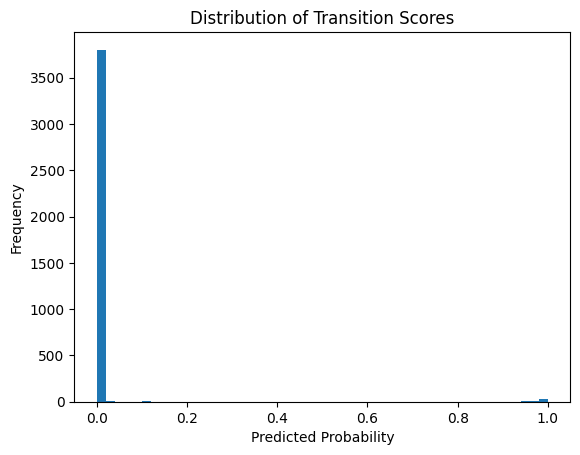

In [19]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(probs, bins=50)
plt.title("Distribution of Transition Scores")
plt.xlabel("Predicted Probability")
plt.ylabel("Frequency")
plt.show()

In [20]:
good_scores = probs[y_test == 1]
bad_scores = probs[y_test == 0]

plt.figure()
plt.hist(good_scores, bins=30, alpha=0.5)
plt.hist(bad_scores, bins=30, alpha=0.5)
plt.title("Good vs Bad Transition Scores")
plt.xlabel("Probability")
plt.ylabel("Count")
plt.legend(["Good", "Bad"])
plt.show()

IndexError: boolean index did not match indexed array along dimension 0; dimension is 3880 but corresponding boolean dimension is 13

In [ ]:
import numpy as np

feature_names = skrillex_cols
feature_importance = np.mean(X, axis=0)

plt.figure()
plt.barh(feature_names, feature_importance)
plt.title("Average Feature Differences")
plt.xlabel("Magnitude")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, preds)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix")
plt.show()

In [ ]:
top_scores = [score for _, _, score in results[:20]]

plt.figure()
plt.plot(top_scores, marker='o')
plt.title("Top Transition Scores")
plt.xlabel("Rank")
plt.ylabel("Score")
plt.show()

In [ ]:
tempo_diffs = X_phrases[:, 0]

plt.figure()
plt.scatter(tempo_diffs, probs, alpha=0.3)
plt.title("Tempo Difference vs Transition Score")
plt.xlabel("Tempo Difference")
plt.ylabel("Predicted Score")
plt.show()

In [ ]:
from IPython.display import Audio, display

def play_phrase(idx):
    file, feat = phrase_features[idx]
    path = os.path.join(audio_folder, file)
    y, sr = librosa.load(path, sr=22050)
    phrases = get_phrases(y, sr)
    
    count = 0
    for f in audio_files:
        path_f = os.path.join(audio_folder, f)
        y_f, sr_f = librosa.load(path_f, sr=22050)
        p_list = get_phrases(y_f, sr_f)
        
        for p in p_list:
            if count == idx:
                print(f"Playing phrase {idx} from {f}")
                display(Audio(p, rate=sr_f))
                return
            count += 1

In [ ]:
play_phrase(0)
play_phrase(10)
play_phrase(50)